# Лабораторная работа № 2.6
---
«Классификация изображений на примере распознавания цифр»

Рязанцев Георгий Борисович

## 1. Импорт базы данных цифр

In [2]:
from sklearn.datasets import load_digits
import pylab as pl

## 2. Загрузка цифр

In [3]:
numbers = load_digits()

In [4]:
# Дополнительно: параметры загруженного набора (в методичке отсутствует)
import numpy as np

print('Изображений:', len(numbers.images), '| форма массива images:', numbers.images.shape)
print('Размер одного изображения:', numbers.images[0].shape, '| число пикселей:', numbers.images[0].size)
print('Значения пикселей: от', numbers.images.min(), 'до', numbers.images.max())
print('Классы (цифры):', [int(c) for c in numbers.target_names])
print('Изображений каждой цифры:', dict(zip(*[a.tolist() for a in np.unique(numbers.target, return_counts = True)])))
print('Метки первых 12 изображений:', numbers.target[:12])

Изображений: 1797 | форма массива images: (1797, 8, 8)
Размер одного изображения: (8, 8) | число пикселей: 64
Значения пикселей: от 0.0 до 16.0
Классы (цифры): [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Изображений каждой цифры: {0: 178, 1: 182, 2: 177, 3: 183, 4: 181, 5: 182, 6: 181, 7: 179, 8: 174, 9: 180}
Метки первых 12 изображений: [0 1 2 3 4 5 6 7 8 9 0 1]


**Результат и отличия от описания в методичке.** В методичке набор называется MNIST и описан тремя признаками, которые не совпадают с реальными значениями. Все расхождения объясняются тем, что функция `load_digits` загружает не MNIST, а другой, меньший набор:

| Что | В методичке | Реальные значения | Почему |
|---|---|---|---|
| Название набора | MNIST: 60 тыс. обучающих и 10 тыс. тестовых изображений | 1797 изображений | `load_digits` возвращает «Optical Recognition of Handwritten Digits» из репозитория UCI (в документации scikit-learn это копия его тестовой части); настоящий MNIST в этой функции не содержится. В практической части методичка сама пишет «порядка 2 тыс. изображений», это и есть 1797 |
| Размер изображения | «64х64» | $8 \times 8 = 64$ пикселя | число 64 в методичке — это количество пикселей, а не сторона квадрата; именно поэтому после `reshape` получается 64 признака |
| Значения пикселей | от 0 до 255 | от 0 до 16 | в этом наборе яркость хранится как целое число от 0 до 16, а не как 8-битный пиксель |

На ход лабораторной это не влияет: классификатор получает матрицу чисел-интенсивностей, и принцип работы тот же. Цифры распределены по классам почти поровну (от 174 до 183 изображений), поэтому набор сбалансирован, а первые 10 изображений имеют метки 0, 1, …, 9 по порядку; это используется в самостоятельной работе.

## 3. Изображение в оттенках серого и его матрица

[[ 0.  0.  5. 13.  9.  1.  0.  0.]
 [ 0.  0. 13. 15. 10. 15.  5.  0.]
 [ 0.  3. 15.  2.  0. 11.  8.  0.]
 [ 0.  4. 12.  0.  0.  8.  8.  0.]
 [ 0.  5.  8.  0.  0.  9.  8.  0.]
 [ 0.  4. 11.  0.  1. 12.  7.  0.]
 [ 0.  2. 14.  5. 10. 12.  0.  0.]
 [ 0.  0.  6. 13. 10.  0.  0.  0.]]


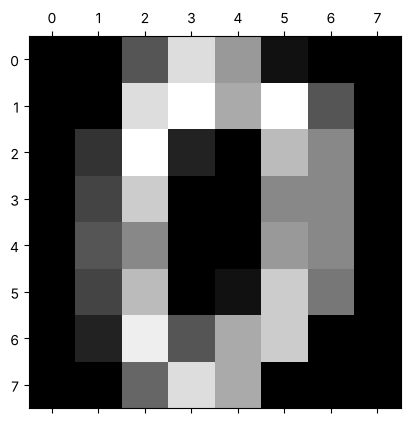

In [5]:
pl.gray() # Изображение преобразуется в набор значений в оттенках серого
pl.matshow(numbers.images[0]) # Сначала выведем изображение
pl.show()
print(numbers.images[0]) # Вывод соответствующей матрицы

**Результат совпадает с рис. 2.49 и 2.50:** на рисунке изображена цифра 0 (метка `numbers.target[0]` равна 0, см. ячейку выше), а матрица $8 \times 8$ совпадает с рис. 2.50 до каждого элемента (первая строка `0. 0. 5. 13. 9. 1. 0. 0.`, последняя `0. 0. 6. 13. 10. 0. 0. 0.`). Значение 0 соответствует чёрному цвету, максимальное значение 16 — белому, поэтому светлые клетки рисунка образуют контур нуля. Модель работает именно с такими числами, а не с картинкой.

## 4. Классификация изображений

In [6]:
# Импортируем требуемые библиотеки:
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import confusion_matrix
import pylab as plt

# Выберем целевую переменную
Y = numbers.target

# Подготовим данные
n_samples = len(numbers.images)

# С применением метода reshape преобразует матричную форму данных.
X = numbers.images.reshape((n_samples, -1))

# Разобьем данные на тестовый и тренировочный набор
X_train, X_test, y_train, y_test = train_test_split(X, Y, random_state=0)

# Выберем наивный классификатор Байеса, а для оценки вероятности – распределение Гаусса
GB = GaussianNB()
# Подготовим данные
fit = GB.fit(X_train, y_train)
# Проведем прогнозирование по незнакомым данным
predicted_unknown = fit.predict(X_test)
# Создадим и выведем матрицу несоответствий
print(confusion_matrix(y_test, predicted_unknown))

[[37  0  0  0  0  0  0  0  0  0]
 [ 0 39  0  0  0  0  0  0  4  0]
 [ 0  7 20  2  0  0  0  0 15  0]
 [ 0  0  0 39  0  0  0  1  5  0]
 [ 0  1  0  0 31  0  0  6  0  0]
 [ 0  1  0  1  0 43  0  3  0  0]
 [ 0  0  1  0  0  0 51  0  0  0]
 [ 0  0  0  0  1  0  0 47  0  0]
 [ 0  6  0  1  0  1  0  2 38  0]
 [ 0  2  0  4  1  0  0  3  7 30]]


In [7]:
# Дополнительно: размеры выборок, итоговые показатели и самые частые ошибки (в методичке отсутствует)
from sklearn.metrics import accuracy_score, classification_report
print('Форма X:', X.shape, '| обучающая выборка:', X_train.shape, '| тестовая выборка:', X_test.shape)

cm = confusion_matrix(y_test, predicted_unknown)
diag = np.trace(cm)
print('Сумма по главной диагонали:', diag, '| сумма всех остальных элементов:', cm.sum() - diag)
print('Критерий «диагональ больше остальных» выполнен:', diag > cm.sum() - diag)
print('Accuracy на тестовой выборке:', round(accuracy_score(y_test, predicted_unknown), 4))
print('Цифра 6: изображений в тесте', cm[6].sum(), '| распознано верно', cm[6, 6])
print('Строка 2, столбец 1 (цифра 2 принята за 1):', cm[2, 1])
print()
print(classification_report(y_test, predicted_unknown, digits = 3))
errors = sorted(((cm[i, j], i, j) for i in range(10) for j in range(10) if i != j), reverse = True)[:5]
print('Самые частые ошибки (реальная цифра -> ответ модели: сколько раз):')
for count, i, j in errors:
    print('  %d -> %d: %d' % (i, j, count))

Форма X: (1797, 64) | обучающая выборка: (1347, 64) | тестовая выборка: (450, 64)
Сумма по главной диагонали: 375 | сумма всех остальных элементов: 75
Критерий «диагональ больше остальных» выполнен: True
Accuracy на тестовой выборке: 0.8333
Цифра 6: изображений в тесте 52 | распознано верно 51
Строка 2, столбец 1 (цифра 2 принята за 1): 7

              precision    recall  f1-score   support

           0      1.000     1.000     1.000        37
           1      0.696     0.907     0.788        43
           2      0.952     0.455     0.615        44
           3      0.830     0.867     0.848        45
           4      0.939     0.816     0.873        38
           5      0.977     0.896     0.935        48
           6      1.000     0.981     0.990        52
           7      0.758     0.979     0.855        48
           8      0.551     0.792     0.650        48
           9      1.000     0.638     0.779        47

    accuracy                          0.833       450
   macro

**Результат совпадает с рис. 2.51:** матрица ошибок $10 \times 10$ совпадает с рисунком до каждого элемента (разбиение `random_state=0` и `GaussianNB` не содержат случайности, поэтому результат воспроизводится при каждом запуске). Тестовая выборка — 450 изображений (25 % от 1797), обучающая — 1347.

Проверка утверждений методички по реальным значениям:

| Утверждение методички | Реальные значения |
|---|---|
| «Число 6 совпало с верным значением 52 раза» | на главной диагонали для цифры 6 стоит **51**, а число 52 — это количество шестёрок в тестовой выборке (сумма строки): одна шестёрка принята за 2 (элемент в строке 6, столбце 2). Матрица на рис. 2.51 тоже показывает 51, так что неточность в тексте методички, а не в расчёте |
| «Модель предсказывала 1 семь раз, хотя было изображено значение 2 (столбец 1, строка 2)» | совпадает: элемент `cm[2, 1]` равен 7 |
| «Хорошей считается модель, у которой сумма по диагонали превышает сумму всех остальных значений» | выполняется: на диагонали 375, вне диагонали 75, accuracy $375/450 \approx 0{,}833$ |

Качество неравномерно по цифрам: цифры 0 и 6 распознаются почти безошибочно (recall $1{,}000$ и $0{,}981$), а цифра 2 — хуже всего (recall $0{,}455$: из 44 двоек верно распознано только 20, при этом 15 приняты за 8, 7 за 1 и 2 за 3); ответ «8» модель при этом даёт слишком часто (precision $0{,}551$). Это согласуется с рис. 2.52, где единственная двойка из первых семи изображений распознана как 8. Наивный байесовский классификатор считает пиксели независимыми, поэтому похожие по начертанию цифры (2 и 8, 9 и 8, 4 и 7) путает чаще; заметно большей точности от такой простой модели не ожидается; методичка и сама отмечает, что цифра 5 на рис. 2.52 изображена спорно.

## 5. Сравнение прогнозов с реальными цифрами

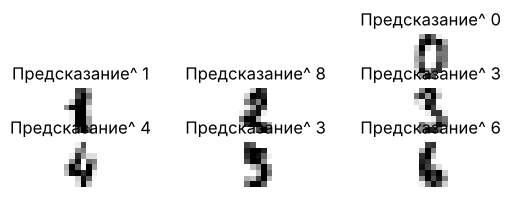

In [8]:
# Сохраним матрицу изображения и прогнозов (в числовом виде) в одном массиве
images_and_predictions = list(zip(numbers.images, fit.predict(X)))
# Перебор первых 7 изображений
for index, (image, prediction) in enumerate(images_and_predictions[:7]):
  plt.subplot(7, 3, index + 6) # Добавление дополнительной поддиаграммы на сетке 7х3
  plt.axis('off') # Ось не отображается
  plt.imshow(image, cmap=plt.cm.gray_r, interpolation='nearest') # Изображение выводится в оттенках серого
  plt.title('Предсказание^ %i' % prediction) # Прогнозируемое значение выводится в заголовке изображения

# Выведем полную диаграмму, состоящую из 7 поддиаграмм.
plt.show()

In [9]:
# Дополнительно: числовые значения к рис. 2.52 и точность на всех изображениях (в методичке отсутствует)
predicted_all = fit.predict(X)
_, idx_test = train_test_split(np.arange(n_samples), random_state = 0)     # номера изображений тестовой выборки (то же разбиение)
print('Номер | реальная цифра | ответ модели | верно | в тестовой выборке')
for i in range(7):
    print('%5d | %14d | %12d | %5s | %s' % (i, Y[i], predicted_all[i], 'да' if predicted_all[i] == Y[i] else 'нет', 'да' if i in idx_test else 'нет'))
print()
print('Accuracy на всех %d изображениях: %.4f (верно %d)' % (n_samples, accuracy_score(Y, predicted_all), (predicted_all == Y).sum()))

Номер | реальная цифра | ответ модели | верно | в тестовой выборке
    0 |              0 |            0 |    да | нет
    1 |              1 |            1 |    да | нет
    2 |              2 |            8 |   нет | да
    3 |              3 |            3 |    да | нет
    4 |              4 |            4 |    да | да
    5 |              5 |            3 |   нет | да
    6 |              6 |            6 |    да | да

Accuracy на всех 1797 изображениях: 0.8514 (верно 1530)


**Результат совпадает с рис. 2.52 и с описанием в методичке:** модель дала ответы 0, 1, 8, 3, 4, 3, 6 для изображений цифр 0, 1, 2, 3, 4, 5, 6. Верно распознаны 0, 1, 3, 4, 6; неверно — 2 (принята за 8) и 5 (принята за 3), как сказано в методичке. Расположение рисунка тоже не ошибка: `subplot(7, 3, index + 6)` занимает на сетке $7 \times 3$ позиции с 6-й по 12-ю, поэтому цифра 0 оказывается в правом верхнем углу, а остальные образуют два ряда по три; символ `^` в заголовках — особенность строки из методички (в рисунке он тоже виден).

Важно: прогноз в этой ячейке строится для **всех** 1797 изображений (`fit.predict(X)`), то есть включает те, на которых модель обучалась (из семи показанных в тестовую выборку попали только 2, 4, 5 и 6). Поэтому accuracy по всем изображениям ($0{,}8514$, верно 1530 из 1797) немного выше, чем на тестовой выборке ($0{,}8333$), и именно тестовый показатель честно оценивает качество на незнакомых данных.

## Самостоятельная работа

Требуется вывести результат классификации для ряда изображений цифр от 0 до 9 с использованием кода работы. Первые 10 изображений набора имеют метки 0, 1, …, 9 по порядку (это проверяется в ячейке), поэтому ряд цифр от 0 до 9 — это `numbers.images[:10]`. Код тот же, что в п. 5 (`fit.predict`, `imshow` с `cmap=plt.cm.gray_r`), только число изображений увеличено с 7 до 10, сетка нормальная ($2 \times 5$), а в заголовке указана и реальная цифра, и ответ модели.

Реальная цифра -> ответ модели
0 -> 0  верно  (обучающая выборка)
1 -> 1  верно  (обучающая выборка)
2 -> 8  ОШИБКА (тестовая выборка)
3 -> 3  верно  (обучающая выборка)
4 -> 4  верно  (тестовая выборка)
5 -> 3  ОШИБКА (тестовая выборка)
6 -> 6  верно  (тестовая выборка)
7 -> 7  верно  (обучающая выборка)
8 -> 8  верно  (обучающая выборка)
9 -> 9  верно  (тестовая выборка)
Верно распознано: 8 из 10


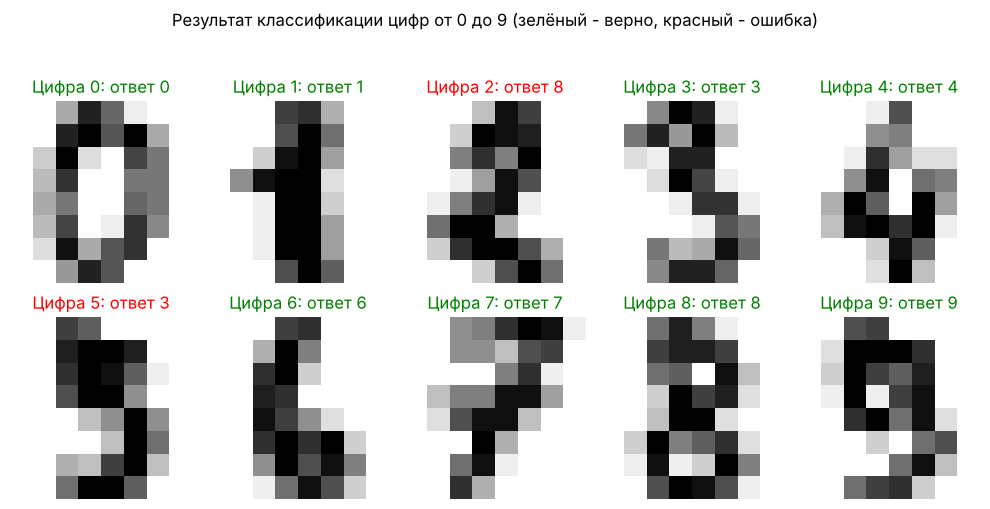

In [10]:
# Самостоятельная работа: результат классификации для ряда цифр от 0 до 9
# Первые 10 изображений набора имеют метки 0, 1, ..., 9 по порядку (проверка):
assert list(numbers.target[:10]) == list(range(10))

predicted_row = fit.predict(X[:10])        # ответ модели для изображений цифр 0-9

fig, axes = plt.subplots(2, 5, figsize = (10, 5.4))
for digit, ax in enumerate(axes.ravel()):
    ok = predicted_row[digit] == Y[digit]
    ax.imshow(numbers.images[digit], cmap = plt.cm.gray_r, interpolation = 'nearest')
    ax.set_title('Цифра %d: ответ %d' % (Y[digit], predicted_row[digit]), color = 'green' if ok else 'red')
    ax.axis('off')
plt.suptitle('Результат классификации цифр от 0 до 9 (зелёный - верно, красный - ошибка)')
plt.tight_layout(rect = (0, 0, 1, 0.95))
plt.show()

print('Реальная цифра -> ответ модели')
for digit in range(10):
    print('%d -> %d  %-6s (%s)' % (Y[digit], predicted_row[digit], 'верно' if predicted_row[digit] == Y[digit] else 'ОШИБКА',
                                  'тестовая выборка' if digit in idx_test else 'обучающая выборка'))
print('Верно распознано:', int((predicted_row == Y[:10]).sum()), 'из 10')

**Результат.** Из десяти цифр верно распознаны восемь: 0, 1, 3, 4, 6, 7, 8, 9. Ошибки две, те же, что на рис. 2.52: цифра 2 принята за 8, цифра 5 — за 3; новые цифры ряда (7, 8, 9) распознаны верно. Из десяти изображений в тестовой выборке находятся только пять (2, 4, 5, 6, 9), остальные модель видела при обучении, поэтому 8 из 10 — иллюстрация работы кода, а не оценка качества. Оценка качества — accuracy $0{,}833$ на 450 тестовых изображениях из п. 4.

## Итоги сверки с методичкой

| Что | В методичке | Реальные значения / комментарий |
|---|---|---|
| Набор данных | MNIST, 60 тыс. + 10 тыс., значения 0–255, «64х64» | `load_digits`: 1797 изображений $8 \times 8$ (64 пикселя), значения 0–16; это не MNIST, а набор UCI; в практической части методичка сама пишет «порядка 2 тыс.» |
| Рис. 2.49, 2.50 | цифра 0 и её матрица | совпадают полностью |
| Выборки | не указаны | обучающая 1347, тестовая 450 изображений (`random_state=0`) |
| Матрица ошибок (рис. 2.51) | приведена на рисунке | совпадает полностью; диагональ 375, вне диагонали 75, accuracy $0{,}833$ |
| «6 совпало 52 раза» | 52 | на диагонали 51; 52 — число шестёрок в тесте |
| «1 предсказана 7 раз при реальной 2» | 7 | совпадает (`cm[2, 1] = 7`) |
| Прогнозы для первых 7 изображений (рис. 2.52) | 0, 1, 8, 3, 4, 3, 6; ошибки 2→8 и 5→3 | совпадают |
| Самостоятельная работа | результат для цифр от 0 до 9 | 8 верных из 10; ошибки 2→8 и 5→3 |